# Proximal Policy Optimization (PPO)

**Research paper:** Schulman et al., *Proximal Policy Optimization Algorithms* (2017), arXiv:1707.06347.

It implements a small discrete-action actor–critic PPO agent directly in NumPy, including manual backpropagation and Adam, and compares:

1. **Unclipped surrogate** (`L^CPI`) — baseline without clipping.
2. **PPO-Clip** (`L^CLIP`) — clipping parameter ε = 0.2.
3. **Adaptive KL penalty** (`L^KLPEN`) — target KL = 0.01.

**Environment:** CartPole-v1 (Gymnasium). **Standard configuration:** 120,000 environment steps, 2,048 steps per rollout, minibatch 64, 10 epochs, learning rate 3e-4, seeds 0–2. **Stress configuration:** learning rate 3e-3, 20 epochs, seeds 0–4, with the same 120,000-step budget.

> **Interpretation boundary:** this is a lightweight reproduction of the PPO mechanism, not an exact reproduction of the paper's MuJoCo/Atari benchmarks. The paper used different environments, policy architectures, and evaluation protocols. CartPole has a discrete action space, so this notebook uses a categorical policy. The numbers in the presentation are the group's reported experiment results; rerunning stochastic RL experiments can produce slightly different values depending on software versions and execution details.

## 1. Paper-to-code map

| Presentation / paper concept | Where it appears in this notebook |
|---|---|
| Probability ratio `r_t(θ) = πθ(a_t|s_t) / πθold(a_t|s_t)` | PPO training loop (`ratio`) |
| Clipped objective `E[min(r A, clip(r, 1−ε, 1+ε) A)]` (Eq. 7) | `variant == "clip"` branch |
| Unclipped importance-sampling baseline (`L^CPI`) | `variant == "unclipped"` branch |
| Adaptive KL penalty and coefficient adjustment | `variant == "klpen"` branch |
| GAE with γ = 0.99 and λ = 0.95 | Rollout / advantage calculation |
| Multiple shuffled minibatch epochs per rollout | `run()` |
| Manual MLP backpropagation and Adam | MLP / optimizer cell |

The network is a 4–64–64–2 categorical policy and a 4–64–64–1 value function. The policy/value networks and Adam optimizer are implemented in NumPy. This notebook uses one environment instance and is intentionally smaller in scope than the paper's parallel MuJoCo and Atari experiments.

## 2. Environment setup

Run this cell in a fresh environment if the dependencies are missing. Gymnasium's classic-control package provides CartPole. On a local machine, you may need to restart the kernel after installing packages.

In [7]:
import sys
from pathlib import Path

venv_site = Path('/Users/yashasvichanda/Downloads/.venv/lib/python3.13/site-packages')
if venv_site.exists():
    sys.path.insert(0, str(venv_site))

print("Python:", sys.version.split()[0])
print("Using local venv:", venv_site)


Python: 3.13.5
Using local venv: /Users/yashasvichanda/Downloads/.venv/lib/python3.13/site-packages


In [8]:
import json
import time
import numpy as np
import matplotlib.pyplot as plt

try:
    import gymnasium as gym
except ImportError as exc:
    raise ImportError("Install dependencies with `%pip install gymnasium[classic-control]` and rerun this cell.") from exc

STANDARD_SEEDS = [0, 1, 2]
STRESS_SEEDS = [0, 1, 2, 3, 4]
np.set_printoptions(precision=4, suppress=True)
print("NumPy:", np.__version__)
print("Gymnasium:", gym.__version__)

NumPy: 2.5.3
Gymnasium: 1.4.0


## 3. MLP, backpropagation, and Adam

To make the implementation inspectable, the networks and optimizer are written in NumPy rather than delegated to a deep-learning framework. The network supports a batched forward pass, manual backpropagation, global gradient-norm clipping, and Adam updates.

In [9]:
class MLP:
    def __init__(self, sizes, rng, last_scale=1.0):
        self.W, self.b = [], []
        for i, (fan_in, fan_out) in enumerate(zip(sizes[:-1], sizes[1:])):
            scale = last_scale if i == len(sizes) - 2 else 1.0
            self.W.append(rng.normal(0, scale / np.sqrt(fan_in), (fan_in, fan_out)))
            self.b.append(np.zeros(fan_out))
        self.params = self.W + self.b
        self.m = [np.zeros_like(p) for p in self.params]
        self.v = [np.zeros_like(p) for p in self.params]
        self.t = 0

    def forward(self, x):
        cache, h = [x], x
        for k in range(len(self.W)):
            h = h @ self.W[k] + self.b[k]
            if k < len(self.W) - 1:
                h = np.tanh(h)
            cache.append(h)
        return h, cache

    def backward(self, dout, cache):
        L = len(self.W)
        gW, gb, d = [None] * L, [None] * L, dout
        for k in range(L - 1, -1, -1):
            gW[k] = cache[k].T @ d
            gb[k] = d.sum(axis=0)
            if k > 0:
                d = (d @ self.W[k].T) * (1 - cache[k] ** 2)
        return gW + gb

    def step(self, grads, lr, max_norm=0.5):
        norm = np.sqrt(sum(float((g * g).sum()) for g in grads))
        if norm > max_norm:
            grads = [g * max_norm / (norm + 1e-8) for g in grads]
        self.t += 1
        for i, (p, g) in enumerate(zip(self.params, grads)):
            self.m[i] = 0.9 * self.m[i] + 0.1 * g
            self.v[i] = 0.999 * self.v[i] + 0.001 * (g * g)
            m_hat = self.m[i] / (1 - 0.9 ** self.t)
            v_hat = self.v[i] / (1 - 0.999 ** self.t)
            p -= lr * m_hat / (np.sqrt(v_hat) + 1e-8)


def softmax(logits):
    z = logits - logits.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

## 4. PPO training loop

Each iteration collects a fixed-length rollout, estimates advantages with GAE(λ), and reuses that batch for multiple epochs of shuffled minibatch updates. The three objective variants use the same environment, network shape, rollout length, optimizer, and seed set within each configuration; only the policy objective differs.

**Presentation-aligned settings:** γ = 0.99, λ = 0.95, ε = 0.2, target KL = 0.01, rollout = 2,048 steps, minibatch = 64. The standard run uses learning rate 3e-4 and 10 epochs; the stress run uses learning rate 3e-3 and 20 epochs.

**Implementation detail:** time-limit truncations are bootstrapped from the value function when calculating the TD residual, while episode boundaries stop the GAE trace.

In [10]:
def run(variant, seed, total_steps=120_000, n_steps=2048, epochs=10, mb=64,
        lr=3e-4, clip=0.2, gamma=0.99, lam=0.95, beta=1.0, d_targ=0.01,
        render_mode=None):
    """Train one PPO variant on CartPole-v1 and return iteration-level diagnostics."""
    if variant not in ("unclipped", "clip", "klpen"):
        raise ValueError("variant must be 'unclipped', 'clip', or 'klpen'")
    rng = np.random.default_rng(seed)
    env = gym.make("CartPole-v1", render_mode=render_mode)
    obs, _ = env.reset(seed=seed)
    policy = MLP([4, 64, 64, 2], rng, last_scale=0.01)
    value_fn = MLP([4, 64, 64, 1], rng, last_scale=1.0)

    log = {"steps": [], "return": [], "kl": [], "clipfrac": [], "beta": []}
    episode_return, last_mean_return, steps_done = 0.0, 0.0, 0
    try:
        while steps_done < total_steps:
            horizon = min(n_steps, total_steps - steps_done)
            O = np.zeros((horizon, 4)); A = np.zeros(horizon, dtype=int)
            LOGP_OLD = np.zeros(horizon); P_OLD = np.zeros((horizon, 2))
            V = np.zeros(horizon); R = np.zeros(horizon); D = np.zeros(horizon)
            NEXT_V = np.zeros(horizon); finished = []

            for t in range(horizon):
                logits, _ = policy.forward(obs[None, :])
                probs = softmax(logits)[0]
                action = int(rng.choice(2, p=probs))
                value = float(value_fn.forward(obs[None, :])[0][0, 0])
                O[t], A[t], LOGP_OLD[t], P_OLD[t], V[t] = obs, action, np.log(probs[action] + 1e-12), probs, value
                next_obs, reward, terminated, truncated, _ = env.step(action)
                episode_return += reward
                done = terminated or truncated
                # Bootstrap only when the episode ended due to a time limit, not a true terminal state.
                next_value = float(value_fn.forward(next_obs[None, :])[0][0, 0]) if truncated and not terminated else 0.0
                R[t], D[t], NEXT_V[t] = reward, float(done), next_value
                obs = next_obs
                if done:
                    finished.append(episode_return)
                    episode_return = 0.0
                    obs, _ = env.reset()
            steps_done += horizon

            # Generalized Advantage Estimation (GAE): delta_t = r_t + gamma V(s_{t+1}) - V(s_t).
            advantages = np.zeros(horizon); gae = 0.0
            for t in reversed(range(horizon)):
                if D[t]:
                    next_v = NEXT_V[t]
                    continuation = 0.0
                elif t == horizon - 1:
                    next_v = float(value_fn.forward(obs[None, :])[0][0, 0])
                    continuation = 1.0
                else:
                    next_v = V[t + 1]
                    continuation = 1.0
                delta = R[t] + gamma * next_v - V[t]
                gae = delta + gamma * lam * continuation * gae
                advantages[t] = gae
            returns = advantages + V
            advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

            # K epochs of shuffled minibatch optimization.
            for _ in range(epochs):
                permutation = rng.permutation(horizon)
                for start in range(0, horizon, mb):
                    idx = permutation[start:start + mb]
                    n = len(idx)
                    logits, policy_cache = policy.forward(O[idx])
                    probs = softmax(logits)
                    chosen_probs = probs[np.arange(n), A[idx]]
                    ratio = np.exp(np.log(chosen_probs + 1e-12) - LOGP_OLD[idx])
                    adv = advantages[idx]
                    if variant == "clip":
                        clipped_ratio = np.clip(ratio, 1 - clip, 1 + clip)
                        # The clipped branch has zero policy gradient where clipping is active
                        # and the clipped objective is the pessimistic (minimum) branch.
                        active = ~(((adv > 0) & (ratio > 1 + clip)) | ((adv < 0) & (ratio < 1 - clip)))
                        coefficient = adv * ratio * active
                    else:
                        coefficient = adv * ratio
                    one_hot = np.eye(2)[A[idx]]
                    d_objective_d_logits = coefficient[:, None] * (one_hot - probs)
                    if variant == "klpen":
                        # Gradient of -beta * KL(pi_old || pi_new) w.r.t. new logits.
                        d_objective_d_logits -= beta * (probs - P_OLD[idx])
                    # MLP.step performs gradient descent, so negate objective gradient.
                    policy.step(policy.backward(-d_objective_d_logits / n, policy_cache), lr)

                    pred_values, value_cache = value_fn.forward(O[idx])
                    value_grad = (pred_values[:, 0] - returns[idx])[:, None] / n
                    value_fn.step(value_fn.backward(value_grad, value_cache), lr)

            new_probs = softmax(policy.forward(O)[0])
            kl = float(np.mean(np.sum(P_OLD * (np.log(P_OLD + 1e-12) - np.log(new_probs + 1e-12)), axis=1)))
            ratio_all = new_probs[np.arange(horizon), A] / np.exp(LOGP_OLD)
            clipfrac = float(np.mean(np.abs(ratio_all - 1) > clip))
            if variant == "klpen":
                if kl < d_targ / 1.5:
                    beta /= 2
                elif kl > d_targ * 1.5:
                    beta *= 2
            if finished:
                last_mean_return = float(np.mean(finished))
            log["steps"].append(steps_done)
            log["return"].append(last_mean_return)
            log["kl"].append(kl)
            log["clipfrac"].append(clipfrac)
            log["beta"].append(beta)
    finally:
        env.close()
    return log

## 5. Sanity checks before training

These quick checks verify the categorical probabilities, network output shapes, and the clipped objective's expected values. They are implementation checks, not evidence of benchmark-level performance.

In [11]:
# Softmax probabilities should be finite and sum to one.
test_probs = softmax(np.array([[1.0, 2.0], [1000.0, 1001.0]]))
assert np.all(np.isfinite(test_probs))
assert np.allclose(test_probs.sum(axis=1), 1.0)

# Network output shape and finite gradients.
test_net = MLP([4, 64, 64, 2], np.random.default_rng(123), last_scale=0.01)
test_x = np.zeros((5, 4))
test_y, test_cache = test_net.forward(test_x)
assert test_y.shape == (5, 2)
test_grads = test_net.backward(np.ones_like(test_y), test_cache)
assert all(np.all(np.isfinite(g)) for g in test_grads)

# Equation (7): compare unclipped and clipped surrogate terms.
r = np.array([1.5, 0.5, 1.5, 0.5])
a = np.array([1.0, 1.0, -1.0, -1.0])
eps = 0.2
unclipped = r * a
clipped = np.minimum(unclipped, np.clip(r, 1-eps, 1+eps) * a)
print("Unclipped terms:", unclipped)
print("Clipped PPO terms:", clipped)
assert np.all(clipped <= unclipped + 1e-12)
print("Sanity checks passed.")

Unclipped terms: [ 1.5  0.5 -1.5 -0.5]
Clipped PPO terms: [ 1.2  0.5 -1.5 -0.8]
Sanity checks passed.


## 6. Run standard and stress experiments

This cell mirrors the experiment design in slides 8–9. It runs three objectives with three seeds under the standard settings, then three objectives with five seeds under the stress settings. This can take a while because each run performs 120,000 environment steps and multiple epochs of NumPy optimization.

For a quick notebook smoke test, temporarily set `RUN_FULL_EXPERIMENTS = False`; that short test is **not** the result reported in the presentation.

In [12]:
RUN_FULL_EXPERIMENTS = True

STANDARD_CONFIG = {
    "total_steps": 120_000,
    "n_steps": 2048,
    "epochs": 10,
    "mb": 64,
    "lr": 3e-4,
    "clip": 0.2,
    "gamma": 0.99,
    "lam": 0.95,
    "d_targ": 0.01,
}
STRESS_CONFIG = {
    **STANDARD_CONFIG,
    "epochs": 20,
    "lr": 3e-3,
}

if not RUN_FULL_EXPERIMENTS:
    # Quick functional check only; do not use this run for presentation claims.
    STANDARD_CONFIG["total_steps"] = 4_096
    STANDARD_CONFIG["n_steps"] = 512
    STRESS_CONFIG["total_steps"] = 4_096
    STRESS_CONFIG["n_steps"] = 512

def run_experiment_set(config, seeds, label):
    output = {}
    for variant in ("unclipped", "clip", "klpen"):
        output[variant] = []
        for seed in seeds:
            start = time.time()
            history = run(variant=variant, seed=seed, **config)
            output[variant].append(history)
            final_return = history["return"][-1] if history["return"] else float("nan")
            print(f"{label:8s} | {variant:9s} | seed={seed} | final rollout mean return={final_return:.1f} | {time.time()-start:.1f}s")
    return output

standard_results = run_experiment_set(STANDARD_CONFIG, STANDARD_SEEDS, "standard")
stress_results = run_experiment_set(STRESS_CONFIG, STRESS_SEEDS, "stress")

# Keep the standard results under the simple name used by the plotting cells below.
results = standard_results

standard | unclipped | seed=0 | final rollout mean return=500.0 | 9.1s
standard | unclipped | seed=1 | final rollout mean return=500.0 | 8.4s
standard | unclipped | seed=2 | final rollout mean return=500.0 | 8.2s
standard | clip      | seed=0 | final rollout mean return=500.0 | 8.3s
standard | clip      | seed=1 | final rollout mean return=500.0 | 8.2s
standard | clip      | seed=2 | final rollout mean return=500.0 | 8.3s
standard | klpen     | seed=0 | final rollout mean return=500.0 | 8.1s
standard | klpen     | seed=1 | final rollout mean return=500.0 | 8.2s
standard | klpen     | seed=2 | final rollout mean return=500.0 | 8.2s
stress   | unclipped | seed=0 | final rollout mean return=500.0 | 13.0s
stress   | unclipped | seed=1 | final rollout mean return=132.8 | 13.5s
stress   | unclipped | seed=2 | final rollout mean return=386.3 | 13.3s
stress   | unclipped | seed=3 | final rollout mean return=436.0 | 14.0s
stress   | unclipped | seed=4 | final rollout mean return=500.0 | 14.2s
s

## 7. Plot learning curves and update diagnostics

The standard and stress experiments are plotted separately so that the higher learning rate and longer optimization schedule are visible. Return curves show the mean of the most recently completed episode returns recorded at each rollout boundary; shaded bands show standard error across seeds. KL and clip fraction are diagnostics of policy movement, not standalone measures of task success.

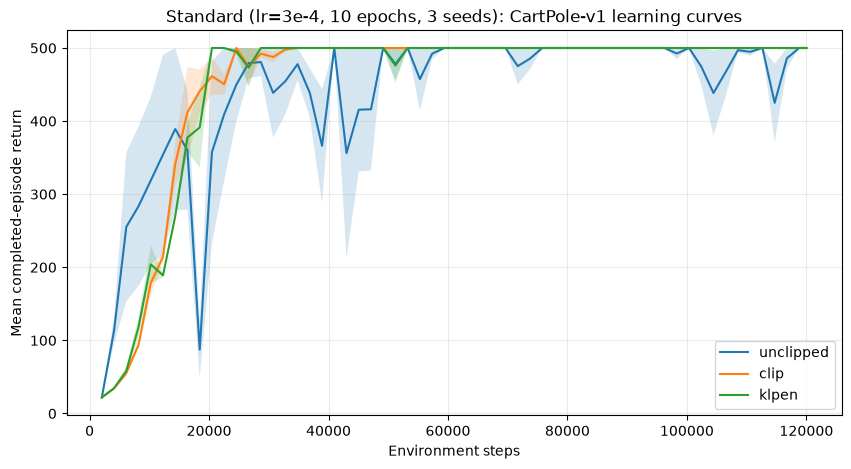

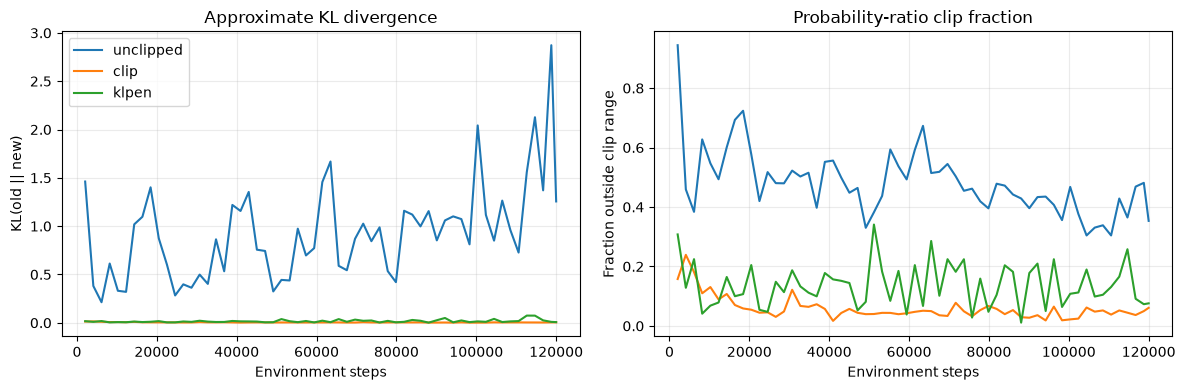

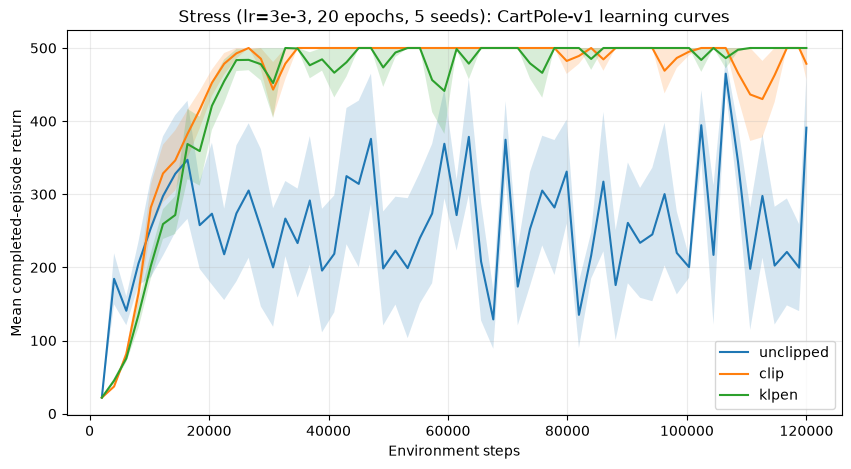

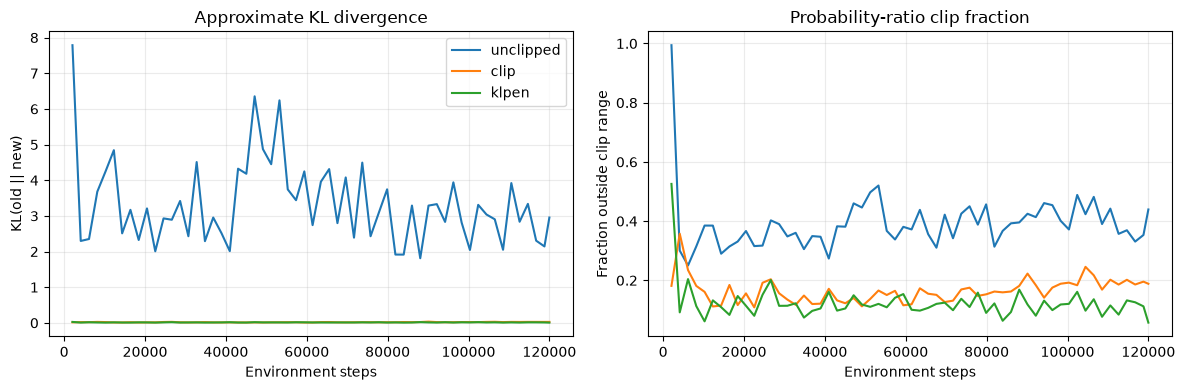

In [13]:
def mean_and_sem(histories, key):
    arrays = [np.asarray(h[key], dtype=float) for h in histories]
    length = min(map(len, arrays))
    matrix = np.stack([a[:length] for a in arrays])
    mean = matrix.mean(axis=0)
    sem = matrix.std(axis=0, ddof=1) / np.sqrt(matrix.shape[0]) if matrix.shape[0] > 1 else np.zeros(length)
    return mean, sem

def plot_diagnostics(result_set, title_prefix):
    fig, ax = plt.subplots(figsize=(10, 5))
    for variant, histories in result_set.items():
        mean, sem = mean_and_sem(histories, "return")
        steps = histories[0]["steps"][:len(mean)]
        ax.plot(steps, mean, label=variant)
        ax.fill_between(steps, mean-sem, mean+sem, alpha=0.18)
    ax.set(title=f"{title_prefix}: CartPole-v1 learning curves", xlabel="Environment steps", ylabel="Mean completed-episode return")
    ax.legend(); ax.grid(alpha=0.25); plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for variant, histories in result_set.items():
        mean_kl, _ = mean_and_sem(histories, "kl")
        mean_cf, _ = mean_and_sem(histories, "clipfrac")
        steps = histories[0]["steps"][:len(mean_kl)]
        axes[0].plot(steps, mean_kl, label=variant)
        axes[1].plot(steps, mean_cf, label=variant)
    axes[0].set(title="Approximate KL divergence", xlabel="Environment steps", ylabel="KL(old || new)")
    axes[1].set(title="Probability-ratio clip fraction", xlabel="Environment steps", ylabel="Fraction outside clip range")
    for ax in axes: ax.grid(alpha=0.25)
    axes[0].legend(); plt.tight_layout(); plt.show()

plot_diagnostics(standard_results, "Standard (lr=3e-4, 10 epochs, 3 seeds)")
plot_diagnostics(stress_results, "Stress (lr=3e-3, 20 epochs, 5 seeds)")

## 8. Summarize results

The table below is calculated from the actual notebook run. Do not hard-code the presentation's values into this table: stochastic training can vary between runs and environments. The presentation reports its own recorded outcomes (including standard and stress final returns and mean KL values); use those exact reported numbers when narrating the existing slides, and describe any new notebook run as a rerun.

In [14]:
def summarize(result_set, experiment_name):
    rows = []
    for variant, histories in result_set.items():
        seed_final_returns = [h["return"][-1] for h in histories if h["return"]]
        all_kls = [float(x) for h in histories for x in h["kl"]]
        rows.append({
            "experiment": experiment_name,
            "variant": variant,
            "mean_final_rollout_return": float(np.mean(seed_final_returns)) if seed_final_returns else float("nan"),
            "std_across_seeds": float(np.std(seed_final_returns, ddof=1)) if len(seed_final_returns) > 1 else 0.0,
            "mean_kl_across_updates": float(np.mean(all_kls)) if all_kls else float("nan"),
            "seeds": len(seed_final_returns),
        })
    return rows

summary = summarize(standard_results, "standard") + summarize(stress_results, "stress")
summary

[{'experiment': 'standard',
  'variant': 'unclipped',
  'mean_final_rollout_return': 500.0,
  'std_across_seeds': 0.0,
  'mean_kl_across_updates': 0.9313030201732687,
  'seeds': 3},
 {'experiment': 'standard',
  'variant': 'clip',
  'mean_final_rollout_return': 500.0,
  'std_across_seeds': 0.0,
  'mean_kl_across_updates': 0.0044325101457442975,
  'seeds': 3},
 {'experiment': 'standard',
  'variant': 'klpen',
  'mean_final_rollout_return': 500.0,
  'std_across_seeds': 0.0,
  'mean_kl_across_updates': 0.01689074784388737,
  'seeds': 3},
 {'experiment': 'stress',
  'variant': 'unclipped',
  'mean_final_rollout_return': 391.02222222222224,
  'std_across_seeds': 152.05878086945907,
  'mean_kl_across_updates': 3.3260912281605624,
  'seeds': 5},
 {'experiment': 'stress',
  'variant': 'clip',
  'mean_final_rollout_return': 478.4666666666666,
  'std_across_seeds': 48.14999711549548,
  'mean_kl_across_updates': 0.018607708754739098,
  'seeds': 5},
 {'experiment': 'stress',
  'variant': 'klpen',


In [15]:
# Save raw histories and summary for reproducibility.
with open("ppo_numpy_results.json", "w") as f:
    json.dump({
        "standard_config": STANDARD_CONFIG,
        "stress_config": STRESS_CONFIG,
        "standard_results": standard_results,
        "stress_results": stress_results,
        "summary": summary,
    }, f, indent=2)
print("Saved ppo_numpy_results.json in the notebook's working directory.")

Saved ppo_numpy_results.json in the notebook's working directory.


## 9. Interpretation and limitations

- **What this demonstrates:** the PPO probability ratio, clipped surrogate, GAE, actor–critic training, repeated minibatch epochs, and adaptive KL penalty are implemented explicitly in NumPy.
- **Configuration alignment:** standard = 120k steps, learning rate 3e-4, 10 epochs, 3 seeds; stress = learning rate 3e-3, 20 epochs, 5 seeds. Both use γ = 0.99, λ = 0.95, ε = 0.2, target KL = 0.01, 2,048 rollout steps, and minibatch 64.
- **Not an exact paper reproduction:** the original paper's headline benchmarks use MuJoCo continuous control and Atari; this implementation uses CartPole-v1 with a categorical policy and a single environment instance.
- **Reproducibility caveat:** fixed seeds improve repeatability, but results may vary with library versions and environment details. The notebook computes its own results; it does not assume that every rerun will reproduce the presentation's exact values.
- **Engineering simplifications:** separate actor and critic networks, no entropy bonus, no parallel actors, and a compact NumPy implementation.
- **Reading the plots:** compare learning stability and policy movement across objectives, but do not generalize from this toy environment or a small number of seeds to all RL tasks.

### Reference
Schulman, J., Wolski, F., Dhariwal, P., Radford, A., & Klimov, O. (2017). *Proximal Policy Optimization Algorithms*. arXiv:1707.06347.